# Heart Murmur Detection

Group: Noa Santos 202201392, Telma Freitas 202301622 and Yunnie Zita 202309709
Professor: Francesco Renna

Each patient of the CirCor DigiScope dataset is classified as murmur **Present**, **Unknown** or
**Absent**, and evaluated with the weighted accuracy of the PhysioNet Challenge 2022.

### Notebook guide
1. [Pre-processing, patient split and evaluation](#pre-processing)
2. [Models](#models): 2.1 CNN, 2.2 RNN
3. [Final model and test set](#final-model)

### Before running

The notebook imports everything from `src/` and expects, from the repository root:

```
pip install -r requirements.txt
aws s3 sync --no-sign-request s3://physionet-open/circor-heart-sound/1.0.3/ data/circor
python -m src.preprocess
```

The README gives other ways to download the data and explains how to run the notebook on Google Colab.
No section trains a CNN by default (see `RUN_TRAINING` in 2.1): the CNN results are read from `results/` and
the final model from `models/`, so the notebook also runs without a GPU.

<a id="pre-processing"></a>
<h2 style="font-family: 'JetBrains Mono', monospace; font-size: 24px; font-weight: 700;">
  <span style="color: #00ff66;">&gt;</span> 1. Pre-processing
</h2>

### Pre-processing, patient split and evaluation

This section walks through, with the real data, everything in commit `dd4d521` ("Add pre-processing pipeline,
patient split and evaluation"). It **does not reimplement anything**: it imports and calls the functions of
`src/` (`features.py`, `data.py`, `evaluate.py`) and shows what each one produces.

Outline:

1. The data: patients, labels and recordings
2. One audio signal, from raw to log-mel (`src/features.py`)
3. MFCC as an alternative to log-mel
4. Patient label vs recording label (`src/data.py`)
5. Patient split (`splits/patient_split.csv`)
6. Cache and normalization statistics (`src/preprocess.py`)
7. `WindowDataset`: windows ready for the network
8. Evaluation: weighted accuracy, confusion matrix and patient-level aggregation (`src/evaluate.py`)

Requirement: the dataset in `data/circor/` and `python -m src.preprocess` already run (cache in `data/cache/`).
The cache steps are only read here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, features, evaluate
from src.data import CLASSES, CACHE_DIR

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Present": "#d6452f", "Unknown": "#8a8a8a", "Absent": "#2a78d6"}
print("raiz do projeto:", ROOT)

raiz do projeto: /content/ml2-heart-murmur


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

### 1.1. The data

The public CirCor DigiScope dataset has 942 patients and 3163 recordings. The `Murmur` label
(Present / Unknown / Absent) belongs to the **patient**; each patient usually has several recordings, one per
auscultation location (aortic, pulmonary, tricuspid and mitral valves).

In [3]:
patients = data.load_patients()
print(patients.shape)
patients.head()

(942, 5)


,patient_id,murmur,murmur_locations,outcome,additional_id
0,2530,Absent,,Abnormal,<NA>
1,9979,Present,AV+MV+PV+TV,Abnormal,<NA>
2,9983,Unknown,,Abnormal,<NA>
3,13918,Present,TV,Abnormal,<NA>
4,14241,Present,AV+MV+PV+TV,Abnormal,<NA>


In [4]:
manifest = pd.read_csv(CACHE_DIR / "manifest.csv")   # gerado por build_manifest em src.preprocess
print(f"{manifest['patient_id'].nunique()} pacientes, {len(manifest)} gravações")
print("gravações por paciente:", manifest.groupby("patient_id").size().value_counts().sort_index().to_dict())
manifest.drop(columns=["wav", "tsv"]).head(8)

942 pacientes, 3163 gravações
gravações por paciente: {1: 62, 2: 156, 3: 123, 4: 588, 5: 10, 6: 3}


,patient_id,recording_id,location,sr,duration_s,ann_start_s,ann_end_s,murmur,murmur_audible,label
0,13918,13918_AV,AV,4000,10.288,1.14675,9.540548,Present,False,Absent
1,13918,13918_PV,PV,4000,9.392,1.21400,6.103365,Present,False,Absent
2,13918,13918_TV,TV,4000,6.592,0.10850,5.580176,Present,True,Present
3,13918,13918_MV,MV,4000,28.784,8.38850,14.243716,Present,False,Absent
4,14241,14241_AV,AV,4000,20.480,9.06250,16.540350,Present,True,Present
5,14241,14241_PV,PV,4000,21.296,5.84025,19.993186,Present,True,Present
6,14241,14241_TV,TV,4000,32.848,5.92225,21.490632,Present,True,Present
7,14241,14241_MV,MV,4000,20.048,5.77550,11.226787,Present,True,Present


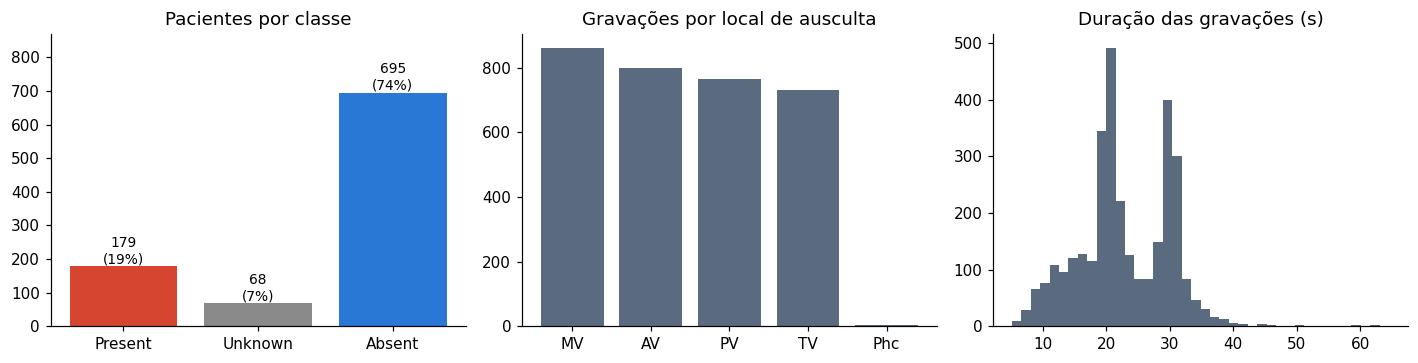

count    3163.0
mean       22.9
std         7.3
min         5.2
25%        19.1
50%        21.5
75%        29.4
max        64.5


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

pc = patients["murmur"].value_counts().reindex(CLASSES)
axes[0].bar(pc.index, pc.values, color=[COLORS[c] for c in pc.index])
axes[0].set_title("Pacientes por classe")
for i, v in enumerate(pc.values): axes[0].text(i, v, f"{v}\n({v/pc.sum():.0%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, pc.max() * 1.25)

loc = manifest["location"].value_counts()
axes[1].bar(loc.index, loc.values, color="#5b6b7f")
axes[1].set_title("Gravações por local de ausculta")

axes[2].hist(manifest["duration_s"], bins=40, color="#5b6b7f")
axes[2].set_title("Duração das gravações (s)")
plt.tight_layout(); plt.show()
print(manifest["duration_s"].describe().round(1).to_string())

**What this shows:** the dataset is very unbalanced (mostly Absent, Unknown is the smallest class) and the
durations vary a lot (from about 5 s to more than 60 s). That is why the pipeline cuts the recordings into
**fixed-length windows**, and the evaluation uses the weighted accuracy, which weighs Present 5x, Unknown 3x and
Absent 1x.

**There are two peaks:** one near 20-21 s and another near 30 s.

### 1.2. From the raw signal to log-mel (`src/features.py`)

Steps per recording:

1. `load_audio`: reads the `.wav` (4000 Hz, mono);
2. `bandpass`: 4th-order Butterworth, zero phase, 25-800 Hz;
3. `normalize_amplitude`: zero mean and unit standard deviation (the stethoscope gain no longer matters);
4. `logmel`: log-mel spectrogram, 64 bands, 50 ms window, 10 ms step (100 frames/s).

We follow each step on a recording with a **Present** murmur.

In [6]:
# Paciente Present, no local onde o sopro é audível
present = manifest[(manifest["murmur"] == "Present") & (manifest["murmur_audible"])]
rec = present.iloc[0]
print(rec[["patient_id", "recording_id", "location", "duration_s", "murmur", "label"]].to_string())

raw = features.load_audio(rec["wav"])
print(f"\nsinal bruto: {raw.shape[0]} amostras, sr={features.SR} Hz, min={raw.min():.3f}, max={raw.max():.3f}")

patient_id         13918
recording_id    13918_TV
location              TV
duration_s         6.592
murmur           Present
label            Present

sinal bruto: 26368 amostras, sr=4000 Hz, min=-1.000, max=1.000


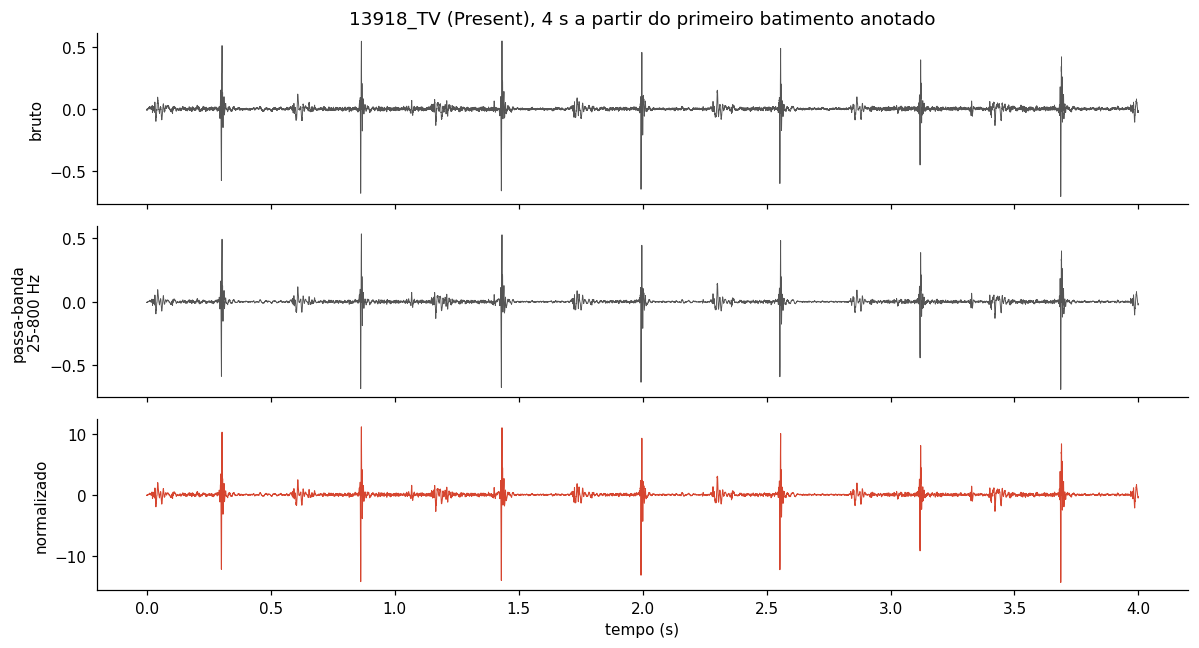

In [7]:
filtered = features.bandpass(raw)
clean = features.normalize_amplitude(filtered)
assert np.allclose(clean, features.preprocess_signal(raw), atol=1e-5)   # preprocess_signal = bandpass + normalize

t0 = rec["ann_start_s"] if not np.isnan(rec["ann_start_s"]) else 0.0
a, b = int(t0 * features.SR), int((t0 + 4) * features.SR)
t = np.arange(b - a) / features.SR

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t, raw[a:b], lw=0.6, color="#555"); axes[0].set_ylabel("bruto")
axes[1].plot(t, filtered[a:b], lw=0.6, color="#555"); axes[1].set_ylabel("passa-banda\n25-800 Hz")
axes[2].plot(t, clean[a:b], lw=0.7, color=COLORS["Present"]); axes[2].set_ylabel("normalizado")
axes[2].set_xlabel("tempo (s)")
axes[0].set_title(f"{rec['recording_id']} ({rec['murmur']}), 4 s a partir do primeiro batimento anotado")
plt.tight_layout(); plt.show()

**Why 25-800 Hz?** Heart sounds sit around 25-200 Hz, and murmurs, even high-pitched ones, reach a few hundred
Hz. Below 25 Hz is movement and handling noise; above 800 Hz is almost only noise. The spectrum below confirms
the effect of the filter.

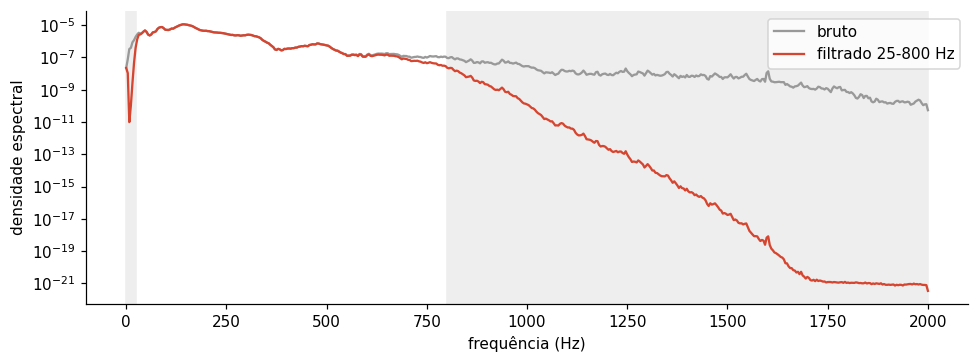

In [8]:
from scipy.signal import welch
f, p_raw = welch(raw, fs=features.SR, nperseg=1024)
_, p_fil = welch(filtered, fs=features.SR, nperseg=1024)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.semilogy(f, p_raw, label="bruto", color="#999")
ax.semilogy(f, p_fil, label="filtrado 25-800 Hz", color=COLORS["Present"])
ax.axvspan(0, 25, color="#eee"); ax.axvspan(800, 2000, color="#eee")
ax.set_xlabel("frequência (Hz)"); ax.set_ylabel("densidade espectral"); ax.legend()
plt.tight_layout(); plt.show()

log-mel: (64, 660) -> 6.6 s a 100 quadros/s


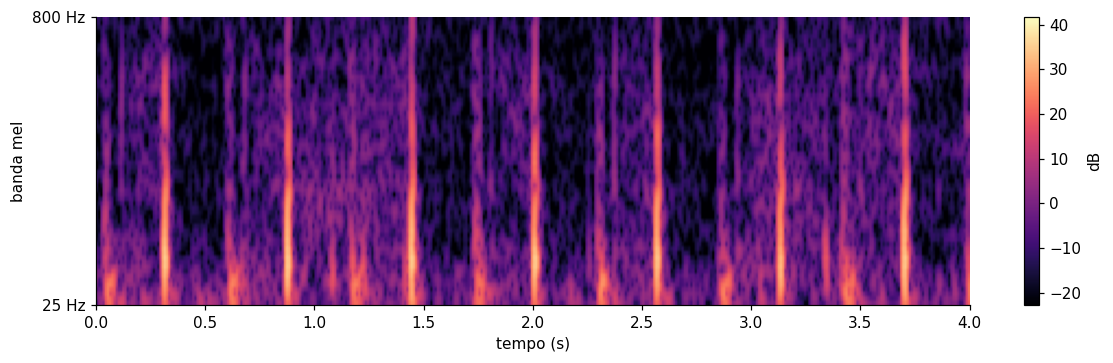

In [9]:
spec = features.logmel(clean)          # (64 bandas, quadros)
print("log-mel:", spec.shape, f"-> {spec.shape[1] / features.FRAMES_PER_SECOND:.1f} s a {features.FRAMES_PER_SECOND:.0f} quadros/s")
assert np.allclose(spec, features.recording_logmel(rec["wav"]), atol=1e-4)   # pipeline completo numa chamada

fr0, fr1 = int(t0 * 100), int((t0 + 4) * 100)
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(spec[:, fr0:fr1], origin="lower", aspect="auto", extent=(0, 4, 0, 64),
               cmap="magma", vmin=np.percentile(spec, 5), vmax=spec.max())
ax.set_yticks([0, 64], ["25 Hz", "800 Hz"]); ax.set_xlabel("tempo (s)"); ax.set_ylabel("banda mel")
plt.colorbar(im, label="dB"); plt.tight_layout(); plt.show()

The same `(64, frames)` matrix feeds both models: the **CNN** reads a window as an image `(1, 64, 400)`; the
**RNN** reads it as a sequence of 400 vectors of 64 values.

### Quick comparison, Absent vs Present

Two recordings from different patients, same pipeline.

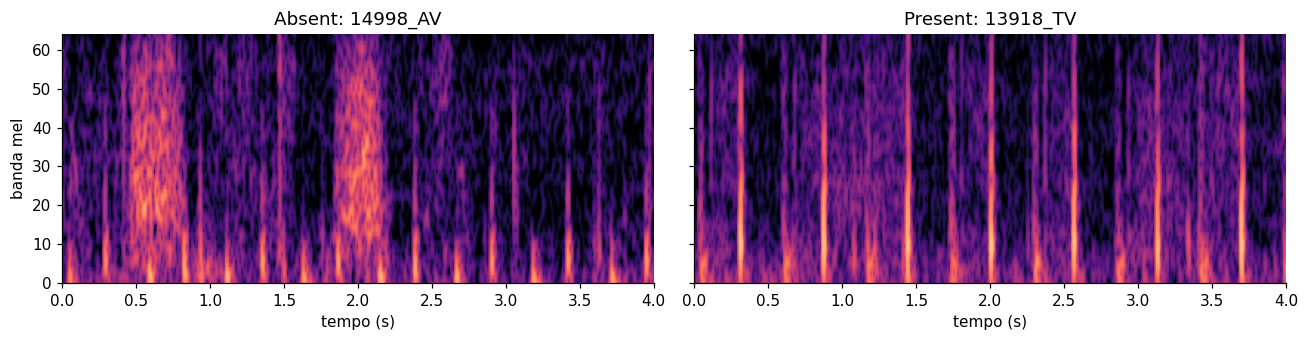

In [10]:
absent = manifest[manifest["murmur"] == "Absent"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, r in zip(axes, [absent, rec]):
    s = features.recording_logmel(r["wav"])
    st = 0 if np.isnan(r["ann_start_s"]) else int(r["ann_start_s"] * 100)
    ax.imshow(s[:, st:st + 400], origin="lower", aspect="auto", extent=(0, 4, 0, 64), cmap="magma",
              vmin=np.percentile(s, 5), vmax=s.max())
    ax.set_title(f"{r['murmur']}: {r['recording_id']}"); ax.set_xlabel("tempo (s)")
axes[0].set_ylabel("banda mel")
plt.tight_layout(); plt.show()

### 1.3. MFCC as an alternative feature

`mfcc_from_logmel` applies the DCT to the log-mel and keeps 20 coefficients, plus 20 deltas (change over time),
40 rows in total. It is one of the pre-processing variants to compare on validation.

log-mel: (64, 660) | MFCC + deltas: (40, 660)
n_features('logmel') = 64 | n_features('mfcc') = 40


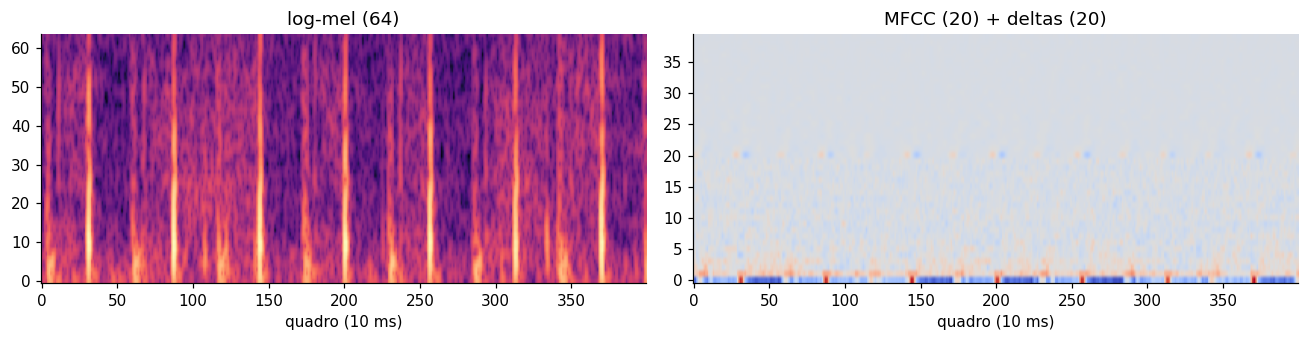

In [11]:
mfcc = features.mfcc_from_logmel(spec)
print("log-mel:", spec.shape, "| MFCC + deltas:", mfcc.shape)
print("n_features('logmel') =", features.n_features("logmel"), "| n_features('mfcc') =", features.n_features("mfcc"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].imshow(spec[:, fr0:fr1], origin="lower", aspect="auto", cmap="magma"); axes[0].set_title("log-mel (64)")
axes[1].imshow(mfcc[:, fr0:fr1], origin="lower", aspect="auto", cmap="coolwarm"); axes[1].set_title("MFCC (20) + deltas (20)")
for ax in axes: ax.set_xlabel("quadro (10 ms)")
plt.tight_layout(); plt.show()

### 1.4. Patient label vs recording label (`src/data.py`)

The project asks for **one prediction per patient**. But a Present patient often has an audible murmur at only
some locations (`Murmur locations`). Training with "Present" on every recording would teach the model that a
normal sound is a murmur. So, **for training**, `recording_label` marks as Absent the recording of a Present
patient at a location where the murmur was not heard. Unknown and Absent pass the label to every recording.
The evaluation always uses the patient label.

In [12]:
ex = manifest[manifest["murmur"] == "Present"].merge(patients[["patient_id", "murmur_locations"]], on="patient_id")
pid = ex.groupby("patient_id").filter(lambda g: g["murmur_audible"].nunique() == 2)["patient_id"].iloc[0]
print(f"Paciente {pid}, rótulo do paciente = Present")
ex[ex["patient_id"] == pid][["recording_id", "location", "murmur_locations", "murmur_audible", "label"]]

Paciente 13918, rótulo do paciente = Present


,recording_id,location,murmur_locations,murmur_audible,label
0,13918_AV,AV,TV,False,Absent
1,13918_PV,PV,TV,False,Absent
2,13918_TV,TV,TV,True,Present
3,13918_MV,MV,TV,False,Absent


In [13]:
print("Rótulo do paciente vs rótulo de treino por gravação:")
pd.crosstab(manifest["murmur"], manifest["label"]).reindex(index=CLASSES, columns=CLASSES)

Rótulo do paciente vs rótulo de treino por gravação:


label,Present,Unknown,Absent
murmur,,,
Present,499,0,117
Unknown,0,156,0
Absent,0,0,2391


The *Present* row loses recordings to the *Absent* column: these are the recordings from locations without an audible murmur.

### 1.5. Patient split

`make_patient_split`: 70/15/15, stratified by `Murmur`, `seed=42`. The file `splits/patient_split.csv` is
versioned, so **the whole group trains and evaluates on the same patients**. Splitting by patient (and not by
recording) avoids leakage, since recordings of the same patient are very similar.

Some children appear twice, under two patient IDs (the `Additional ID` column of the CirCor data). `subject_groups`
puts both IDs of the same child in the same subset, so the same child is never in two subsets. Result: 654
patients in train, 146 in validation and 142 in test.

In [14]:
split = data.load_split()
print(split.shape)
tab = pd.crosstab(split["split"], split["murmur"]).reindex(index=["train", "val", "test"], columns=CLASSES)
tab["total"] = tab.sum(axis=1)
display(tab)
display((tab[list(CLASSES)].div(tab["total"], axis=0) * 100).round(1).add_suffix(" %"))

(942, 3)


murmur,Present,Unknown,Absent,total
split,,,,
train,122,46,486,654
val,28,13,105,146
test,29,9,104,142


murmur,Present %,Unknown %,Absent %
split,,,
train,18.7,7.0,74.3
val,19.2,8.9,71.9
test,20.4,6.3,73.2


In [15]:
# Verificações de integridade do split
sets = {s: set(split.loc[split["split"] == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
assert set(manifest["patient_id"]) == set(split["patient_id"])
# todas as gravações de um paciente caem no mesmo conjunto
rec_split = manifest.merge(split[["patient_id", "split"]], on="patient_id")
assert rec_split.groupby("patient_id")["split"].nunique().max() == 1
print("OK: nenhum paciente em dois conjuntos; recordings de cada paciente ficam juntas.")

# reproduz o split a partir da semente
again = data.make_patient_split(patients, val_size=0.15, test_size=0.15, seed=42)
print("make_patient_split(seed=42) reproduz o arquivo versionado:", again.equals(split))

OK: nenhum paciente em dois conjuntos; recordings de cada paciente ficam juntas.


make_patient_split(seed=42) reproduz o arquivo versionado: True


### 1.6. Cache and normalization statistics (`src/preprocess.py`)

`python -m src.preprocess` does three things, only read here:

- saves one log-mel per recording in `data/cache/band25-800/logmel/<recording_id>.npy`;
- creates the split, if it does not exist yet;
- computes the mean and standard deviation **per row** of the log-mel and the MFCC using **only the training
  recordings**, in `logmel_stats.npz` and `mfcc_stats.npz`. Using only the training set keeps validation and
  test information out of the normalization.

variante: band25-800
arquivos no cache: ['logmel', 'logmel_stats.npz', 'mfcc_stats.npz']
log-mel em cache: 3163 arquivos
variantes de banda em cache: ['band25-800']


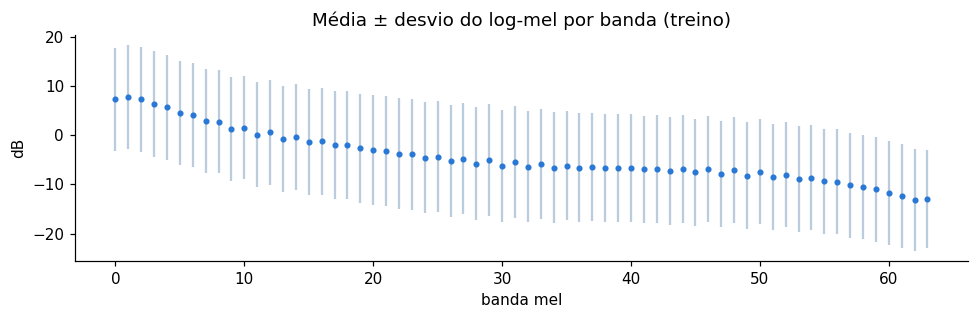

In [16]:
variant = features.variant_name()
print("variante:", variant)
print("arquivos no cache:", sorted(p.name for p in (CACHE_DIR / variant).iterdir()))
print("log-mel em cache:", len(list((CACHE_DIR / variant / "logmel").glob("*.npy"))), "arquivos")
print("variantes de banda em cache:", sorted(p.name for p in CACHE_DIR.iterdir() if p.is_dir()))

mean, std = data.load_feature_stats("logmel")
fig, ax = plt.subplots(figsize=(9, 3))
ax.errorbar(range(64), mean, yerr=std, fmt="o", ms=3, color="#2a78d6", ecolor="#bcd")
ax.set_xlabel("banda mel"); ax.set_ylabel("dB"); ax.set_title("Média ± desvio do log-mel por banda (treino)")
plt.tight_layout(); plt.show()

### 1.7. `WindowDataset`: windows ready for the network

Each item is `(x, y, rec_idx)`:

- `x`: a `(64, 400)` window (4 s at 100 frames/s), already standardized with the training statistics;
- `y`: class index of the **recording label** (`Present=0, Unknown=1, Absent=2`);
- `rec_idx`: which recording the window came from, used later to aggregate per recording and per patient.

Windows move forward 2 s at a time (`window_starts`); an extra window aligned to the end keeps the tail.

In [17]:
print("window_starts(n_frames=1030, win=400, hop=200) ->", data.window_starts(1030, 400, 200))

train_rec = data.get_split_manifest(manifest, split, "train")
val_rec = data.get_split_manifest(manifest, split, "val")
test_rec = data.get_split_manifest(manifest, split, "test")

train_ds = data.WindowDataset(train_rec, window_s=4.0, hop_s=2.0)
val_ds = data.WindowDataset(val_rec)
test_ds = data.WindowDataset(test_rec)
print(f"janelas: treino {len(train_ds)}, val {len(val_ds)}, teste {len(test_ds)}")

x, y, i = train_ds[0]
print("uma janela:", tuple(x.shape), x.dtype, "| classe:", CLASSES[y], "| gravação:", train_ds.recordings.loc[i, "recording_id"])
print(f"padronizada: média {x.mean():.2f}, desvio {x.std():.2f}")

window_starts(n_frames=1030, win=400, hop=200) -> [0, 200, 400, 600, 630]


janelas: treino 24063, val 5333, teste 5176
uma janela: (64, 400) torch.float32 | classe: Absent | gravação: 23625_AV
padronizada: média 0.29, desvio 1.03


In [18]:
from torch.utils.data import DataLoader
loader = DataLoader(train_ds, batch_size=64, shuffle=True)
xb, yb, ib = next(iter(loader))
print("batch:", tuple(xb.shape), "-> (batch, bandas, quadros)")
print("para CNN 2D :", tuple(xb.unsqueeze(1).shape), "-> (batch, 1, 64, 400)")
print("para RNN    :", tuple(xb.transpose(1, 2).shape), "-> (batch, 400 passos, 64 features)")
print("train_ds.n_features =", train_ds.n_features)

batch: (64, 64, 400) -> (batch, bandas, quadros)
para CNN 2D : (64, 1, 64, 400) -> (batch, 1, 64, 400)
para RNN    : (64, 400, 64) -> (batch, 400 passos, 64 features)
train_ds.n_features = 64


In [19]:
# Desbalanceamento visto pelo modelo: janelas por classe em cada conjunto
rows = []
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    lab = np.array([ds.labels[r] for r in ds.window_recordings()])
    rows.append(pd.Series({c: (lab == k).sum() for k, c in enumerate(CLASSES)}, name=name))
win_tab = pd.DataFrame(rows)
display(win_tab)
print("Peso sugerido por classe no treino (inverso da frequência):")
w = 1 / win_tab.loc["train"]; print((w / w.sum() * 3).round(2).to_dict())

,Present,Unknown,Absent
train,3620,1078,19365
val,819,377,4137
test,984,207,3985


Peso sugerido por classe no treino (inverso da frequência):
{'Present': 0.66, 'Unknown': 2.22, 'Absent': 0.12}


### Pre-processing variants

Each choice is an argument of `WindowDataset`, so the variants can be compared **on validation**, changing one
thing at a time:

In [20]:
variants = {
    "padrão (logmel, 4 s)":       dict(),
    "janela 2 s / passo 1 s":     dict(window_s=2.0, hop_s=1.0),
    "janela 6 s / passo 3 s":     dict(window_s=6.0, hop_s=3.0),
    "MFCC + deltas":              dict(feature="mfcc"),
    "corte nas bordas sem anotação (só treino)": dict(trim_to_annotation=True),
}
rows = []
for name, kw in variants.items():
    ds = data.WindowDataset(train_rec, **kw)
    rows.append({"variante": name, "janelas": len(ds), "formato de x": tuple(ds[0][0].shape)})
pd.DataFrame(rows)

,variante,janelas,formato de x
0,"padrão (logmel, 4 s)",24063,"(64, 400)"
1,janela 2 s / passo 1 s,49238,"(64, 200)"
2,janela 6 s / passo 3 s,15643,"(64, 600)"
3,MFCC + deltas,24063,"(40, 400)"
4,corte nas bordas sem anotação (só treino),14798,"(64, 400)"


In [21]:
bands = sorted(p.name for p in CACHE_DIR.iterdir() if p.is_dir())
print("Bandas já em cache:", bands)
if "band25-400" in bands:
    ds = data.WindowDataset(train_rec, band=(25, 400))
    print("Banda 25-400 Hz:", len(ds), "janelas, x =", tuple(ds[0][0].shape))

Bandas já em cache: ['band25-800']


### 1.8. Evaluation (`src/evaluate.py`)

#### 1.8.1 Weighted accuracy and confusion matrix

PhysioNet 2022 metric, at the patient level:

$$WA = \frac{5\,m_{PP} + 3\,m_{UU} + m_{AA}}{5(m_{PP}+m_{UP}+m_{AP}) + 3(m_{PU}+m_{UU}+m_{AU}) + (m_{PA}+m_{UA}+m_{AA})}$$

where `m_ij` is the number of patients predicted as `i` whose true class is `j`. The matrix has
**rows = predicted** and **columns = true**. We start with the trivial classifiers, which set the bar: a model is
only useful if it beats them by a clear margin.

In [22]:
labels = split.set_index("patient_id")["murmur"]      # rótulo real de cada paciente
val_labels = labels[split.loc[split["split"] == "val", "patient_id"]]

rows = {}
for c in CLASSES:
    m = evaluate.classification_metrics(val_labels.to_numpy(), np.full(len(val_labels), c))
    rows[f"sempre {c}"] = round(m["weighted_accuracy"], 3)
print("Acurácia ponderada dos classificadores triviais (validação):")
pd.Series(rows).to_frame("WA")

Acurácia ponderada dos classificadores triviais (validação):


,WA
sempre Present,0.493
sempre Unknown,0.137
sempre Absent,0.370


In [23]:
# Oráculo e um erro de exemplo, para ver a matriz e a métrica funcionando
y_true = val_labels.to_numpy()
perfect = evaluate.classification_metrics(y_true, y_true)
print("Previsão perfeita:", perfect["weighted_accuracy"])

y_pred = y_true.copy()
# os 5 primeiros Present viram Absent
idx = np.where(y_true == "Present")[0][:5]
y_pred[idx] = "Absent"
m = evaluate.classification_metrics(y_true, y_pred)
print(evaluate.format_metrics(m))
print("\nErrar 5 Present custa:", round(perfect["weighted_accuracy"] - m["weighted_accuracy"], 3), "de WA")

Previsão perfeita: 1.0
Weighted accuracy: 0.912
Accuracy: 0.966   macro F1: 0.960
Recall: Present 0.82  Unknown 1.00  Absent 1.00
              true Present  true Unknown  true Absent
pred Present            23             0            0
pred Unknown             0            13            0
pred Absent              5             0          105

Errar 5 Present custa: 0.088 de WA


#### 1.8.2 From window to patient

Flow: **window -> recording -> patient**.

1. `window_probabilities(model, dataset)` gives the probability of the 3 classes for each window;
2. `recording_probabilities` takes the **mean** over the windows of each recording;
3. `patient_predictions` combines the recordings of the patient. Hierarchical rule (default): Present if *some*
   recording has P(Present) >= `t_present`; otherwise Unknown if some recording has P(Unknown) >= `t_unknown`;
   otherwise Absent. This makes sense because a murmur can be audible at a single location. `rule="mean"` uses
   the mean over the recordings.
4. `tune_thresholds` picks `t_present` and `t_unknown` **on validation**; the test set is only used at the end,
   with fixed thresholds.

To show the flow before any training, we use an **untrained** network below (random weights). The trained models
come in section 2.

In [24]:
import tempfile
import torch, torch.nn as nn
torch.manual_seed(0)

untrained = nn.Sequential(nn.Flatten(), nn.Linear(64 * 400, 3))   # pesos aleatórios, nunca treinada

def rec_probs(ds):
    wp, wrec = evaluate.window_probabilities(untrained, ds)
    print(f"  {len(wp)} janelas -> prob. média por gravação ({len(ds.recordings)} gravações)")
    return evaluate.recording_probabilities(wp, wrec, len(ds.recordings))

print("val:");  val_rp = rec_probs(val_ds)
print("test:"); test_rp = rec_probs(test_ds)
pd.DataFrame(val_rp[:5], columns=[f"P({c})" for c in CLASSES]).assign(recording=val_ds.recordings["recording_id"][:5].values)

val:


  5333 janelas -> prob. média por gravação (491 gravações)
test:


  5176 janelas -> prob. média por gravação (477 gravações)


,P(Present),P(Unknown),P(Absent),recording
0,0.522896,0.231645,0.245459,14241_AV
1,0.458644,0.248507,0.292850,14241_PV
2,0.322531,0.340618,0.336852,14241_TV
3,0.390987,0.311369,0.297644,14241_MV
4,0.343969,0.312330,0.343701,36327_AV


In [25]:
# 1) limiares escolhidos SÓ na validação
t_p, t_u, val_wa = evaluate.tune_thresholds(val_rp, val_ds.recordings["patient_id"], labels)
print(f"limiares: t_present={t_p}, t_unknown={t_u}  (WA na validação, otimista: {val_wa:.3f})")

# 2) números finais no teste, com limiares fixos
pred = evaluate.patient_predictions(test_rp, test_ds.recordings["patient_id"], t_present=t_p, t_unknown=t_u)
print(f"\n{len(pred)} pacientes no teste, uma predição por paciente")
display(pred.head())

metrics = evaluate.evaluate_patients(pred, labels)
print(evaluate.format_metrics(metrics))

limiares: t_present=0.3, t_unknown=0.55  (WA na validação, otimista: 0.514)

142 pacientes no teste, uma predição por paciente


,patient_id,murmur,mean_p_Present,mean_p_Unknown,mean_p_Absent,max_p_Present,max_p_Unknown,max_p_Absent
0,13918,Present,0.364182,0.313258,0.322560,0.483278,0.429156,0.397139
1,14998,Present,0.455073,0.247540,0.297388,0.512122,0.296128,0.324952
2,40058,Present,0.375524,0.304132,0.320344,0.409743,0.339898,0.355307
3,49574,Present,0.348010,0.356514,0.295476,0.475611,0.432245,0.352336
4,49585,Present,0.291632,0.341491,0.366877,0.359206,0.437436,0.414336


Weighted accuracy: 0.554
Accuracy: 0.261   macro F1: 0.167
Recall: Present 1.00  Unknown 0.00  Absent 0.08
              true Present  true Unknown  true Absent
pred Present            29             9           95
pred Unknown             0             0            1
pred Absent              0             0            8


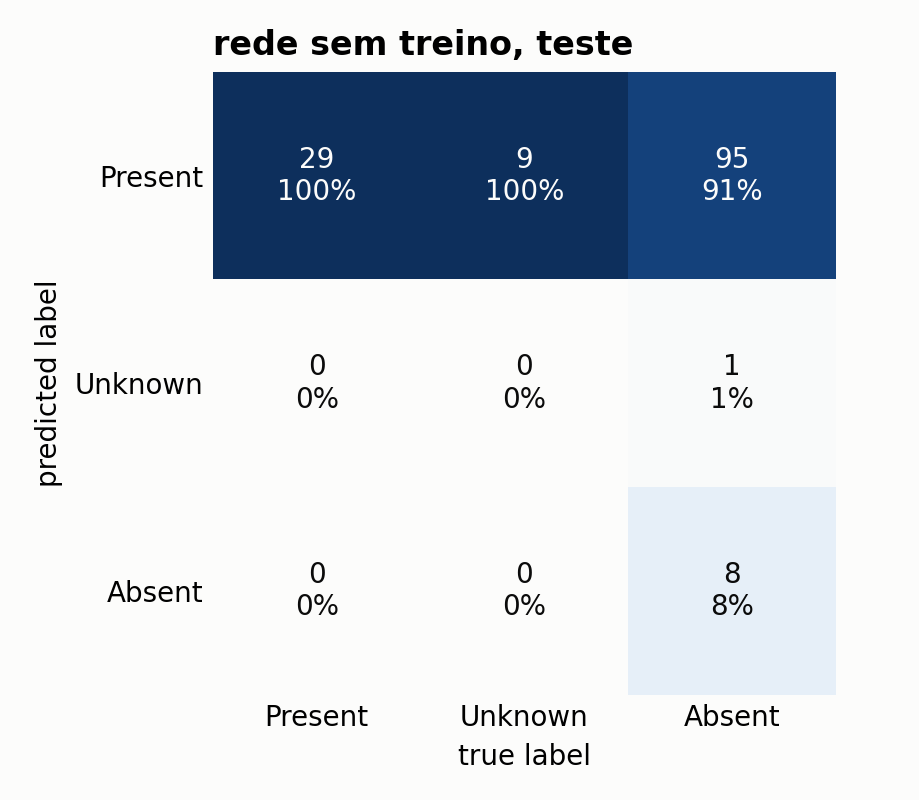

In [26]:
out = Path(tempfile.gettempdir()) / "cm_demo.png"
evaluate.plot_confusion_matrix(metrics["confusion_matrix"], out, "rede sem treino, teste")
from IPython.display import Image
Image(filename=str(out), width=420)

**How to read this:** this random network scores close to the trivial classifier because the metric rewards
predicting Present: with tuned thresholds, "almost everything Present" already gets near the WA of always
predicting Present (0.493 on validation, 0.525 on test). This section shows that the evaluation code works; the
numbers that matter come with the trained models.

#### 1.8.3 Aggregation rules and submission file

In [27]:
pred_mean = evaluate.patient_predictions(test_rp, test_ds.recordings["patient_id"], rule="mean")
print("Regra hierárquica :", round(metrics["weighted_accuracy"], 3))
print("Regra da média    :", round(evaluate.evaluate_patients(pred_mean, labels)["weighted_accuracy"], 3))

# formato do CSV de submissão (patient_id, murmur); escrito em arquivo temporário para não poluir submission/
tmp = Path(tempfile.gettempdir()) / "predictions_demo.csv"
evaluate.save_submission(pred, tmp)
print("\n", tmp.read_text().splitlines()[:4], "...")

Regra hierárquica : 0.554
Regra da média    : 0.319



 ['patient_id,murmur', '13918,Present', '14998,Present', '40058,Present'] ...


<a id="models"></a>
<h2 style="font-family: 'JetBrains Mono', monospace; font-size: 24px; font-weight: 700;">
  <span style="color: #00ff66;">&gt;</span> 2. Models
</h2>

### 2.1. CNN

We started from a small 2D CNN and then changed the model in larger steps: data augmentation, a pretrained
network, a 1D CNN over time, and a CNN followed by a recurrent layer (CRNN). Every experiment was trained with 3
seeds and compared on validation by the mean and standard deviation of the patient-level weighted accuracy.

The code lives in `src/`:

- `models.py`: the 4 architectures;
- `train.py`: SpecAugment, training loop with early stopping, checkpoints;
- `experiments.py`: the list of the 8 training experiments and the 5 ensembles;
- `final_evaluation.py`: ensemble choice and test-set evaluation;
- `plots.py`: training curves and the results chart.

In [28]:
%matplotlib inline
from src import experiments, final_evaluation, models, plots
from src import train as T
from src.models import build_model, count_parameters

device = T.get_device()
print("device:", device)

# the 4 architectures on one real window
window = train_ds[0][0].unsqueeze(0)
rows = []
for name in models.ARCHITECTURES:
    net, prepare = build_model(name, **({"pretrained": False} if name == "resnet18" else {}))
    rows.append({"architecture": name, "input": tuple(prepare(window).shape),
                 "output": tuple(net.eval()(prepare(window)).shape), "parameters": count_parameters(net)})
pd.DataFrame(rows)

device: cpu


,architecture,input,output,parameters
0,cnn2d,"(1, 1, 64, 400)","(1, 3)",98019
1,cnn1d,"(1, 64, 400)","(1, 3)",309699
2,crnn,"(1, 64, 400)","(1, 3)",219203
3,resnet18,"(1, 3, 64, 400)","(1, 3)",11178051


**The architectures**

- **2D CNN** (98 thousand parameters): 4 blocks of 3x3 convolution, batch normalization, ReLU and max pooling.
  The window is a grey image; filters slide over frequency and time.
- **ResNet18** (11.2 million): pretrained on ImageNet photos, with a new 3-class output layer. The window is
  repeated over 3 channels because the network expects colour images. Optionally, the first layer groups are
  frozen.
- **1D CNN** (310 thousand): the 64 mel bands are the channels and the filters (5 frames, 50 ms) slide over time
  only. Sound is treated as a sequence rather than a picture.
- **CRNN** (219 thousand): 3 blocks of the 1D CNN reduce the 400 frames to 50 steps of 80 ms, then a
  bidirectional GRU reads those 50 steps in both directions. A GRU keeps a memory that gates decide to keep or
  overwrite, so it can relate events far apart in the window, such as a murmur and the heartbeats around it.

**Training, the same for every experiment:** cross-entropy weighted by the inverse class frequency of the windows,
Adam (weight decay 1e-4), batches of 64, at most 30 epochs. After each epoch, the window probabilities are
averaged per recording, the thresholds are tuned on validation and the patient-level WA is computed; training
stops after 6 epochs without improvement and keeps the best epoch.

In [29]:
print("class weights (Present, Unknown, Absent):", T.class_weights(train_ds).round(2))

class weights (Present, Unknown, Absent): [2.22 7.44 0.41]


**Data augmentation: SpecAugment.** During training only, each window gets 2 random frequency strips (up to 8
bands) and 2 random time strips (up to 40 frames, 0.4 s) set to 0, which is the training mean after
standardization. The model cannot rely on one narrow detail and has to use the whole pattern.

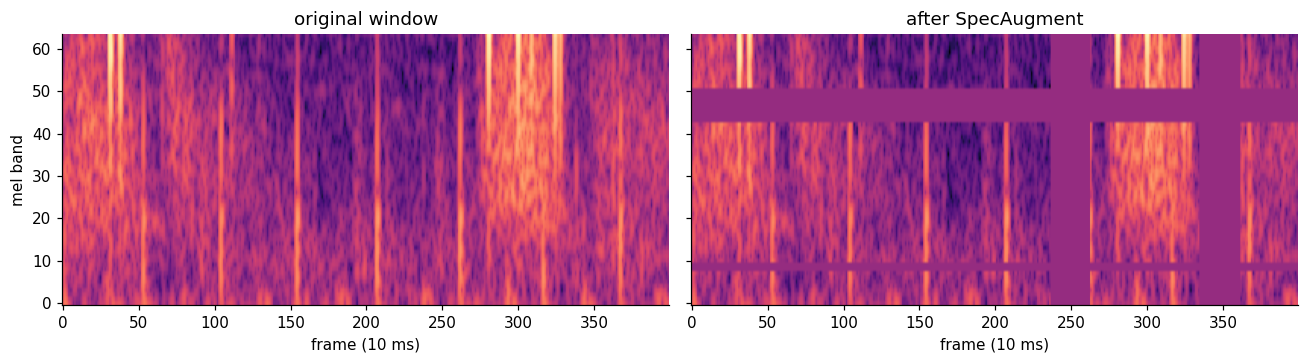

In [30]:
torch.manual_seed(0)
w = train_ds[0][0]
plots.plot_spec_augment(w, T.spec_augment(w.unsqueeze(0))[0])
plt.show()

#### 2.1.1 Experiments

All the experiments are defined in `src/experiments.py`. Every experiment except the baseline uses SpecAugment.

Training all 24 runs (8 experiments x 3 seeds) takes about 2 hours on a GPU and much longer on a CPU, so by
default the cell below does not train and the next cells read the saved results from `results/`. Set
`RUN_TRAINING = True` to retrain; a single run is `experiments.run_experiment("crnn_specaug", seed=42)`, or
`python -m src.experiments crnn_specaug` from a terminal.

In [31]:
pd.DataFrame(experiments.EXPERIMENTS).T.fillna("")

/tmp/ipykernel_3603/3656211430.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  pd.DataFrame(experiments.EXPERIMENTS).T.fillna("")


,architecture,augment,lr,description,model_kwargs,clip
cnn_base,cnn2d,False,0.00100,"2D CNN baseline, no augmentation",,
cnn_specaug,cnn2d,True,0.00100,2D CNN with SpecAugment,,
resnet18_specaug,resnet18,True,0.00010,"ResNet18 pretrained on ImageNet, all layers tr...",,
resnet18_specaug_lr3e-5,resnet18,True,0.00003,"ResNet18 pretrained, lower learning rate",,
resnet18_freeze2_specaug,resnet18,True,0.00010,"ResNet18 pretrained, stem + layer1-2 frozen",{'freeze': 2},
resnet18_freeze3_specaug,resnet18,True,0.00010,"ResNet18 pretrained, stem + layer1-3 frozen",{'freeze': 3},
cnn1d_specaug,cnn1d,True,0.00100,"1D CNN (bands as channels, filters over time)",,
crnn_specaug,crnn,True,0.00100,CRNN: 3 Conv1d blocks + bidirectional GRU,,1.0


In [32]:
RUN_TRAINING = False

if RUN_TRAINING:
    for name in experiments.EXPERIMENTS:
        for seed in experiments.SEEDS:
            experiments.run_experiment(name, seed, train_ds, val_ds, device=device)
else:
    print("Not training: using the saved results in results/ (set RUN_TRAINING = True to retrain).")

Not training: using the saved results in results/ (set RUN_TRAINING = True to retrain).


#### 2.1.2 Validation results

One row per experiment: mean and standard deviation of the best validation WA over the 3 seeds, the epoch where
early stopping found the best model, and the time per epoch on a Colab T4 GPU.

In [33]:
cnn_runs = pd.read_csv(T.RESULTS_DIR / "experiments.csv")
cnn_summary = (cnn_runs.groupby("experiment", sort=False)
               .agg(val_wa_mean=("best_val_wa", "mean"), val_wa_std=("best_val_wa", "std"),
                    best_epochs=("best_epoch", list), parameters=("parameters", "first"),
                    trainable=("trainable_parameters", "first"), seconds_per_epoch=("seconds_per_epoch", "mean"))
               .reindex(list(experiments.EXPERIMENTS)))
cnn_summary.round(3)

,val_wa_mean,val_wa_std,best_epochs,parameters,trainable,seconds_per_epoch
experiment,,,,,,
cnn_base,0.749,0.017,"[14, 3, 10]",98019,98019,18.767
cnn_specaug,0.759,0.008,"[15, 5, 9]",98019,98019,19.033
resnet18_specaug,0.797,0.011,"[2, 1, 2]",11178051,11178051,52.533
resnet18_specaug_lr3e-5,0.776,0.011,"[6, 3, 4]",11178051,11178051,52.600
resnet18_freeze2_specaug,0.784,0.027,"[13, 7, 7]",11178051,10494979,30.367
resnet18_freeze3_specaug,0.754,0.009,"[2, 6, 4]",11178051,8395267,25.767
cnn1d_specaug,0.782,0.004,"[3, 7, 2]",309699,309699,8.333
crnn_specaug,0.808,0.011,"[7, 13, 3]",219203,219203,9.167


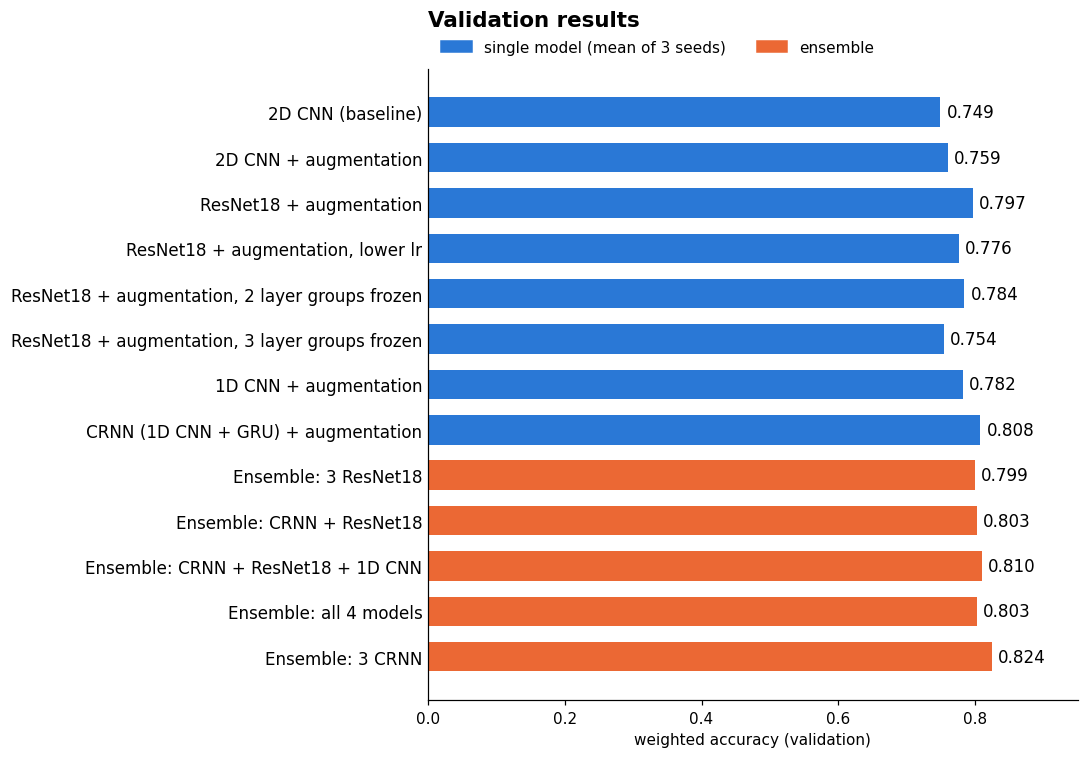

In [34]:
ensemble_table = pd.read_csv(T.RESULTS_DIR / "ensembles.csv")
plots.plot_results(cnn_runs, ensemble_table)
plt.show()

**Training curves.** Three runs (seed 42) show the typical pattern: the training loss keeps falling while the
validation WA stops improving after a few epochs. The ResNet18 reaches its best epoch almost at once and then
memorizes the training patients. The curves of all 24 runs are in `results/figures/training/`.

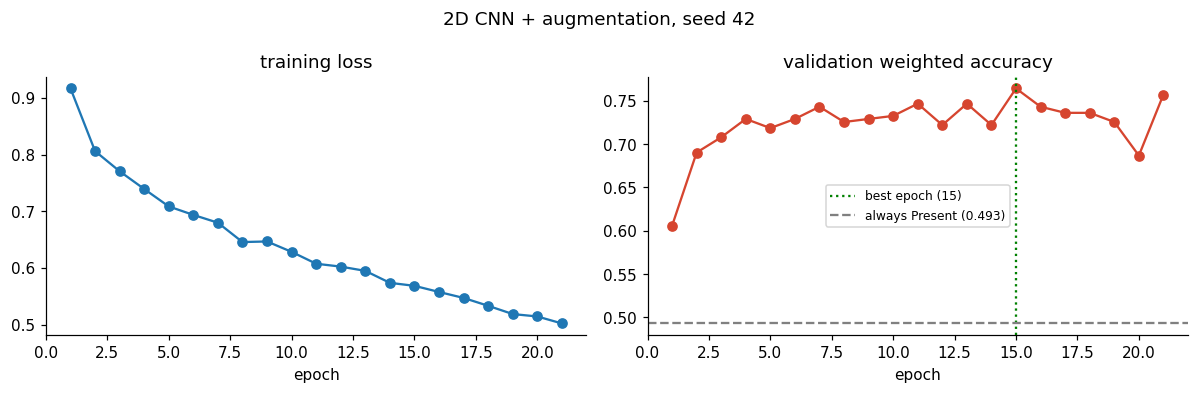

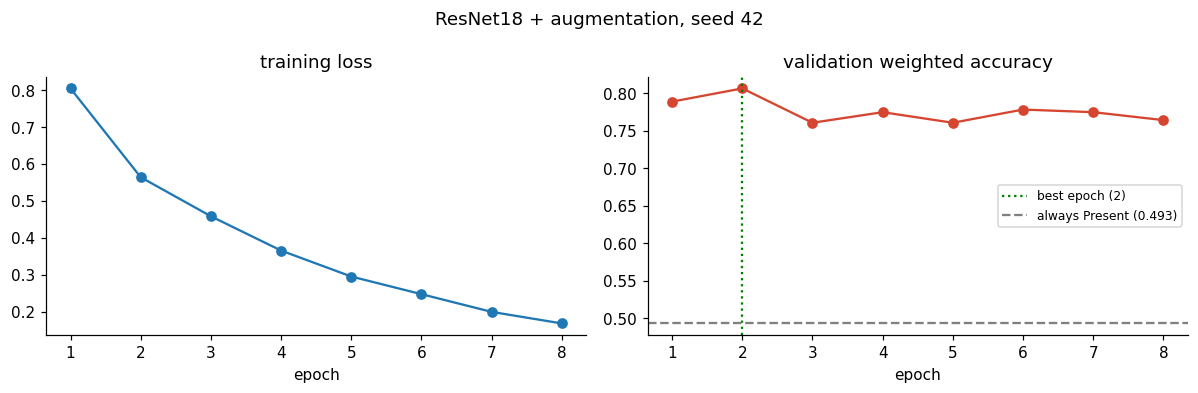

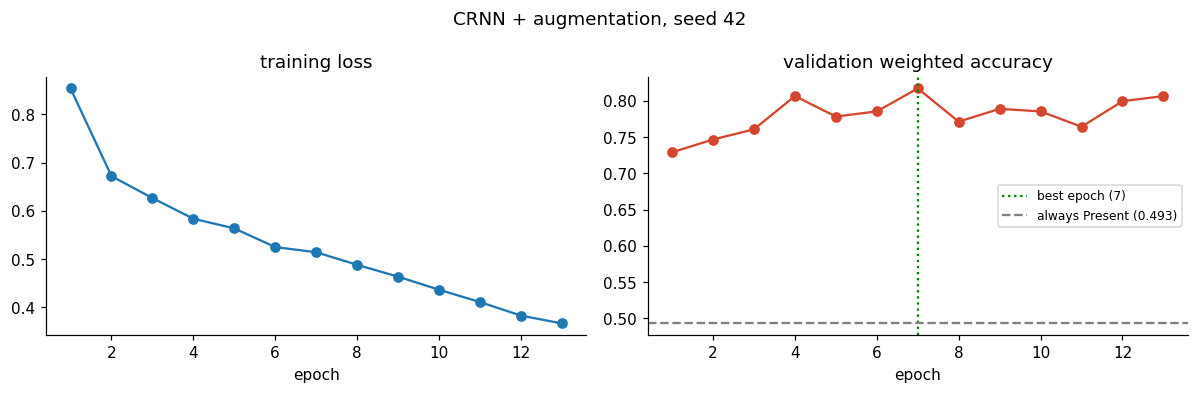

In [35]:
for run, title in [("cnn_specaug", "2D CNN + augmentation"), ("resnet18_specaug", "ResNet18 + augmentation"),
                   ("crnn_specaug", "CRNN + augmentation")]:
    row = cnn_runs[(cnn_runs["experiment"] == run) & (cnn_runs["seed"] == 42)].iloc[0]
    history = pd.read_csv(T.RESULTS_DIR / "histories" / f"{run}_seed42.csv")
    plots.plot_training(history, row["best_epoch"], f"{title}, seed 42")
    plt.show()

#### 2.1.3 What the experiments show

**What helped**

- **SpecAugment.** The mean rose only slightly (0.749 to 0.759), but the spread between seeds dropped from 0.017
  to 0.008: the result depends much less on the seed.
- **Pretraining (ResNet18, 0.797).** Features learned from photos, such as edges and textures, transfer to
  spectrograms.
- **Treating the sound as a sequence (1D CNN, 0.782).** Filters that slide only along time beat the 2D CNN, and
  train about 6 times faster than ResNet18.
- **Reading the order of events (CRNN, 0.808).** Adding the GRU to the 1D CNN gave +0.026; the only difference
  between the two is that the GRU reads the steps in order instead of averaging them. The CRNN matches ResNet18
  with 50 times fewer parameters and no pretraining.

**What did not help**

- **Lower learning rate for ResNet18 (0.776).** Learning more slowly did not stop the overfitting; the model
  learned less before early stopping.
- **Freezing ResNet18 layers (0.784 with 2 groups, 0.754 with 3).** Freezing the first two groups fixes only 6%
  of the weights, so the network still memorizes, and freezing three groups lowers the score: spectrograms look
  nothing like photos, so the deeper layers have to adapt.

**Caveats**

- Every model overfits: the training loss keeps falling while the validation WA stops improving. Early stopping
  keeps the best epoch.
- Validation has 146 patients, so the WA moves by about 0.02-0.04 between epochs. Differences of about 0.01 are
  within that noise, which is why each experiment uses 3 seeds.

### 2.2. RNN - Recurrent Neural Network

Step by step:

1. sequence input: each 4 s window (64 log-mel bands x 400 frames of 10 ms) is read as 400 time steps of 64
   values, or 200 steps after averaging pairs of frames (`time_pool=2`);
2. architectures: simple RNN, GRU and LSTM with the same hidden size (64); then bidirectional, two layers and
   mean pooling on the best of the three;
3. training: cross-entropy weighted by the inverse class frequency, Adam (lr 1e-3), batch 64, gradient
   clipping (norm 1) and early stopping on the validation WA (patience 6);
4. one prediction per patient: the window -> recording -> patient rule of 1.8.2, thresholds tuned on validation;
5. experiments, and the final recurrent model on the test set.

#### 2.2.1. Simple RNN

In [36]:
import copy, time
from torch.utils.data import DataLoader

torch.manual_seed(42); np.random.seed(42)
DEVICE= "cuda" if torch.cuda.is_available() else "cpu"
print("device:",DEVICE)

device: cpu


In [37]:
class SimpleRNN(nn.Module):
    def __init__(self, n_features=64, hidden= 64, num_layers=1, time_pool=1,n_classes=3):
        super().__init__()
        self.time_pool= nn.AvgPool1d(time_pool) if time_pool > 1 else nn.Identity()
        self.rnn = nn.RNN(input_size= n_features, hidden_size= hidden, num_layers= num_layers, nonlinearity="tanh", batch_first=True)
        self.fc= nn.Linear(hidden, n_classes)

    def forward(self,x):
      x= self.time_pool(x)
      x= x.transpose(1,2)
      output, h_n= self.rnn(x)
      return self.fc(h_n[-1])

m= SimpleRNN()
print("saída:", tuple(m(torch.randn(8, 64, 400)).shape))
print("parâmetros:", sum(p.numel() for p in m.parameters()))

saída: (8, 3)
parâmetros: 8515


In [38]:
lab = np.array([train_ds.labels[r] for r in train_ds.window_recordings()])
counts = np.bincount(lab, minlength=3)
class_w = counts.sum() / (3 * counts)
print("janelas P/U/A:", counts, "| pesos:", class_w.round(2))   # esperado ≈ [2.08 6.99 0.42]

janelas P/U/A: [ 3620  1078 19365] | pesos: [2.22 7.44 0.41]


Training

In [39]:
def train_one_epoch(model, loader, loss_fn, optimizer, clip=1.0):
    model.train()
    total, n, gnorms = 0.0, 0, []
    for xb, yb, _ in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)  # norma ANTES do corte
        optimizer.step()
        total += loss.item() * len(xb); n += len(xb)
        gnorms.append(gn.item())
    return total / n, float(np.mean(gnorms))


@torch.no_grad()
def validate(model, ds):
    model.to("cpu")                    # avaliação em CPU: não depende do device dentro de evaluate.py
    model.eval()
    wp, wrec = evaluate.window_probabilities(model, ds)
    model.to(DEVICE)
    rp = evaluate.recording_probabilities(wp, wrec, len(ds.recordings))
    t_p, t_u, wa = evaluate.tune_thresholds(rp, ds.recordings["patient_id"], labels)
    return wa, t_p, t_u


def fit(model, train_ds, val_ds, class_weights=None, epochs=30, lr=1e-3,
        batch_size=64, patience=6, clip=1.0):
    model.to(DEVICE)
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    w = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history, best, bad = [], {"wa": -1.0}, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, gnorm = train_one_epoch(model, loader, loss_fn, optimizer, clip)
        wa, t_p, t_u = validate(model, val_ds)
        dt = time.time() - t0
        history.append({"epoch": ep, "train_loss": tr_loss, "grad_norm": gnorm, "val_wa": wa, "time_s": dt})
        print(f"ep {ep:02d} | loss {tr_loss:.4f} | grad {gnorm:.3f} | val WA {wa:.4f} "
              f"(t_p={t_p}, t_u={t_u}) | {dt:.0f}s")
        if wa > best["wa"]:
            best = {"wa": wa, "epoch": ep, "t_p": t_p, "t_u": t_u,
                    "state": copy.deepcopy(model.state_dict())}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"early stopping (melhor época: {best['epoch']})")
                break
    model.load_state_dict(best["state"])
    return model, best, pd.DataFrame(history)

In [40]:
m = SimpleRNN().to(DEVICE)
xb, yb, _ = next(iter(DataLoader(train_ds, batch_size=64, shuffle=True)))
with torch.no_grad():
    l0 = nn.CrossEntropyLoss()(m(xb.to(DEVICE)), yb.to(DEVICE)).item()
print(f"loss inicial: {l0:.3f}  (esperado ≈ ln 3 = {np.log(3):.3f})")

loss inicial: 1.020  (esperado ≈ ln 3 = 1.099)


In [41]:
idx = np.random.default_rng(0).choice(len(train_ds), size=200, replace=False)
small = DataLoader(Subset(train_ds, idx), batch_size=50, shuffle=True)
m = SimpleRNN(time_pool=4).to(DEVICE)
opt = torch.optim.Adam(m.parameters(), lr=3e-3)
for ep in range(1, 151):
    loss, _ = train_one_epoch(m, small, nn.CrossEntropyLoss(), opt, clip=5.0)
    if ep % 30 == 0:
        print(f"ep {ep:3d}  loss {loss:.4f}")

ep  30  loss 0.0483


ep  60  loss 0.0067


ep  90  loss 0.0024


ep 120  loss 0.0012


ep 150  loss 0.0007


In [42]:
torch.manual_seed(42)
rnn, best_rnn, hist_rnn = fit(SimpleRNN(), train_ds, val_ds, class_weights=class_w)
print(f"melhor val WA = {best_rnn['wa']:.4f} na época {best_rnn['epoch']}")

ep 01 | loss 1.0708 | grad 1.116 | val WA 0.5493 (t_p=0.4, t_u=0.45) | 91s


ep 02 | loss 1.0510 | grad 1.258 | val WA 0.5035 (t_p=0.45, t_u=0.55) | 103s


ep 03 | loss 1.0393 | grad 1.547 | val WA 0.5493 (t_p=0.4, t_u=0.5) | 85s


ep 04 | loss 1.0420 | grad 1.692 | val WA 0.5423 (t_p=0.4, t_u=0.5) | 103s


ep 05 | loss 1.0408 | grad 1.486 | val WA 0.5246 (t_p=0.4, t_u=0.4) | 95s


ep 06 | loss 1.0422 | grad 1.468 | val WA 0.5282 (t_p=0.45, t_u=0.35) | 88s


ep 07 | loss 1.0488 | grad 1.449 | val WA 0.5106 (t_p=0.4, t_u=0.45) | 99s
early stopping (melhor época: 1)
melhor val WA = 0.5493 na época 1


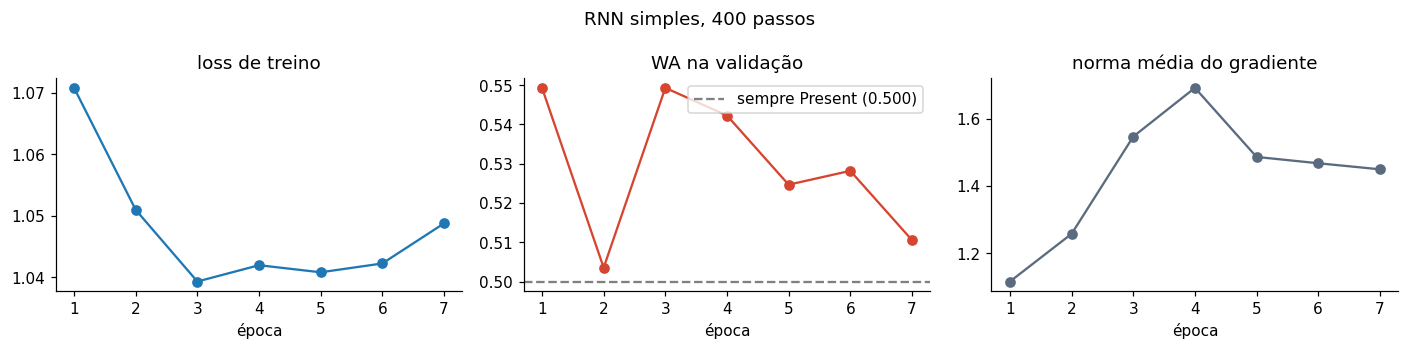

In [43]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    axes[0].plot(hist["epoch"], hist["train_loss"], "o-"); axes[0].set_title("loss de treino")
    axes[1].plot(hist["epoch"], hist["val_wa"], "o-", color="#d6452f")
    axes[1].axhline(0.5, ls="--", color="gray", label="sempre Present (0.500)")
    axes[1].set_title("WA na validação"); axes[1].legend()
    axes[2].plot(hist["epoch"], hist["grad_norm"], "o-", color="#5b6b7f"); axes[2].set_title("norma média do gradiente")
    for ax in axes: ax.set_xlabel("época")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist_rnn, "RNN simples, 400 passos")

ep 01 | loss 1.0484 | grad 1.972 | val WA 0.5458 (t_p=0.35, t_u=0.5) | 68s


ep 02 | loss 1.0345 | grad 1.432 | val WA 0.5317 (t_p=0.3, t_u=0.55) | 73s


ep 03 | loss 1.0187 | grad 1.597 | val WA 0.5669 (t_p=0.5, t_u=0.6) | 73s


ep 04 | loss 1.0256 | grad 1.584 | val WA 0.5775 (t_p=0.45, t_u=0.5) | 72s


ep 05 | loss 1.0135 | grad 1.468 | val WA 0.5563 (t_p=0.4, t_u=0.6) | 75s


ep 06 | loss 1.0069 | grad 1.688 | val WA 0.5634 (t_p=0.45, t_u=0.45) | 67s


ep 07 | loss 1.0315 | grad 1.769 | val WA 0.5599 (t_p=0.45, t_u=0.4) | 75s


ep 08 | loss 1.0314 | grad 1.836 | val WA 0.5634 (t_p=0.5, t_u=0.6) | 72s


ep 09 | loss 1.0372 | grad 2.092 | val WA 0.5352 (t_p=0.4, t_u=0.5) | 65s


ep 10 | loss 1.0130 | grad 1.588 | val WA 0.5352 (t_p=0.25, t_u=0.6) | 68s
early stopping (melhor época: 4)


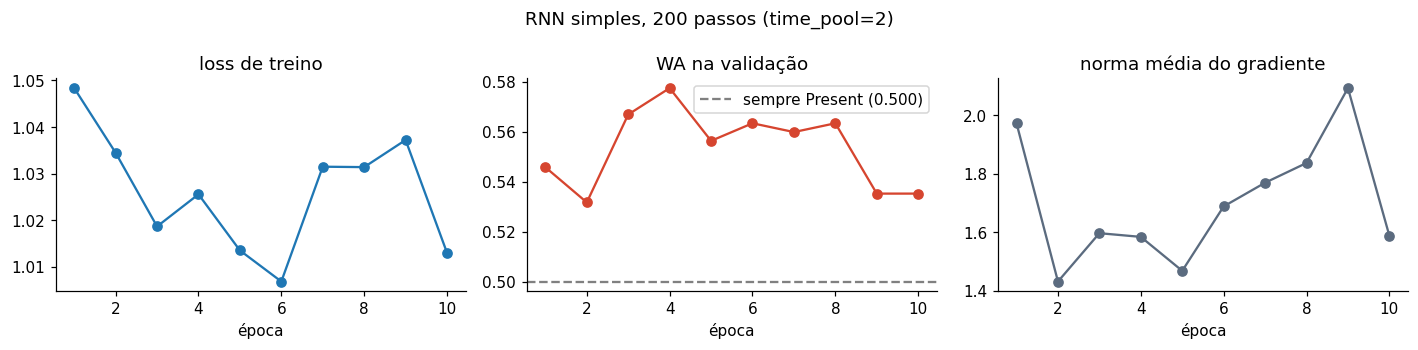

,modelo,passos,parâmetros,melhor val WA,época,s/época
0,RNN simples,400,8515,0.5493,1,94.7
1,"RNN simples, média 2 em 2",200,8515,0.5775,4,70.9


In [44]:
results = []
def register(name, model, best, hist, seq_len):
    results.append({"modelo": name, "passos": seq_len,
                    "parâmetros": sum(p.numel() for p in model.parameters()),
                    "melhor val WA": round(best["wa"], 4), "época": best["epoch"],
                    "s/época": round(hist["time_s"].mean(), 1)})

register("RNN simples", rnn, best_rnn, hist_rnn, 400)

torch.manual_seed(42)
rnn_p2, best_p2, hist_p2 = fit(SimpleRNN(time_pool=2), train_ds, val_ds, class_weights=class_w)
register("RNN simples, média 2 em 2", rnn_p2, best_p2, hist_p2, 200)
plot_history(hist_p2, "RNN simples, 200 passos (time_pool=2)")

pd.DataFrame(results)

#### 2.2.2. GRU and LSTM

One class, `RecurrentClassifier`, covers the three recurrent units, so the comparison changes **only the
cell type**. Features, windows, hidden size (64), learning rate, class weights, early stopping and seed (42)
stay the same as in the simple RNN.

The simple RNN barely beats the trivial classifier (always Present = 0.500): best validation WA 0.549 with 400
steps (best epoch 1) and 0.578 with 200 steps. The mean gradient norm stays above 1 in every epoch, so
gradient clipping is active in practice all the time. The GRU and the LSTM test whether gated units learn
better from the same sequences.

In [ ]:
class RecurrentClassifier(nn.Module):
    # cell: 'rnn' | 'gru' | 'lstm';  pooling: 'last' (final hidden state) | 'mean' (mean of all states)
    def __init__(self, cell="rnn", n_features=64, hidden=64, num_layers=1, bidirectional=False,
                 pooling="last", time_pool=1, dropout=0.0, n_classes=3):
        super().__init__()
        self.cell, self.pooling, self.bidirectional = cell, pooling, bidirectional
        self.time_pool = nn.AvgPool1d(time_pool) if time_pool > 1 else nn.Identity()
        kw = dict(input_size=n_features, hidden_size=hidden, num_layers=num_layers,
                  batch_first=True, bidirectional=bidirectional,
                  dropout=dropout if num_layers > 1 else 0.0)
        if cell == "rnn":
            self.rnn = nn.RNN(nonlinearity="tanh", **kw)
        elif cell == "gru":
            self.rnn = nn.GRU(**kw)
        elif cell == "lstm":
            self.rnn = nn.LSTM(**kw)
        else:
            raise ValueError(f"unknown cell: {cell}")
        out_dim = hidden * (2 if bidirectional else 1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(out_dim, n_classes)

    def forward(self, x):                        # x: (B, F, T)
        x = self.time_pool(x).transpose(1, 2)    # (B, T', F)
        if self.cell == "lstm":
            output, (h_n, c_n) = self.rnn(x)     # the LSTM also returns the cell state c_n
        else:
            output, h_n = self.rnn(x)            # output: (B, T', H*dirs)   h_n: (layers*dirs, B, H)
        if self.pooling == "mean":
            z = output.mean(dim=1)
        elif self.bidirectional:                 # last layer, forward and backward directions
            z = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            z = h_n[-1]
        return self.fc(self.drop(z))             # (B, 3) logits

for c in ["rnn", "gru", "lstm"]:
    m = RecurrentClassifier(cell=c)
    print(f"{c:5s} output {tuple(m(torch.randn(8, 64, 400)).shape)}  parameters {sum(p.numel() for p in m.parameters()):,}")
# expected: rnn 8,515 | gru 25,155 | lstm 33,475

In [ ]:
# Faster validation: if evaluate.window_probabilities accepts a `device` argument, validate on the GPU
# instead of moving the model to the CPU. This redefines `validate`, so `fit` uses it from here on.
import inspect
WP_HAS_DEVICE = "device" in inspect.signature(evaluate.window_probabilities).parameters
print("window_probabilities accepts device:", WP_HAS_DEVICE)

@torch.no_grad()
def validate(model, ds):
    model.eval()
    if WP_HAS_DEVICE:
        model.to(DEVICE)
        wp, wrec = evaluate.window_probabilities(model, ds, device=DEVICE)
    else:
        model.to("cpu")
        wp, wrec = evaluate.window_probabilities(model, ds)
        model.to(DEVICE)
    rp = evaluate.recording_probabilities(wp, wrec, len(ds.recordings))
    t_p, t_u, wa = evaluate.tune_thresholds(rp, ds.recordings["patient_id"], labels)
    return wa, t_p, t_u

In [ ]:
import json

RNN_RESULTS_DIR = ROOT / "results" / "rnn"          # separate folder: CNN results are not touched
RNN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS = {}      # name -> {"model", "best", "hist", "kw"}

def save_experiment(name, best, hist, kw):
    torch.save({"best": best, "kw": kw}, RNN_RESULTS_DIR / f"{name}.pt")
    hist.to_csv(RNN_RESULTS_DIR / f"{name}_history.csv", index=False)

def run_experiment(name, epochs=30, patience=6, lr=1e-3, **model_kw):
    # Trains, or reloads from results/rnn/ if this experiment was already trained
    # (so a Colab disconnect does not mean training everything again).
    ckpt = RNN_RESULTS_DIR / f"{name}.pt"
    model = RecurrentClassifier(n_features=train_ds.n_features, **model_kw)
    if ckpt.exists():
        saved = torch.load(ckpt, map_location="cpu", weights_only=False)
        model.load_state_dict(saved["best"]["state"])
        model.to(DEVICE)
        best, hist = saved["best"], pd.read_csv(RNN_RESULTS_DIR / f"{name}_history.csv")
        print(f"[{name}] loaded from disk: val WA {best['wa']:.4f} (epoch {best['epoch']})")
    else:
        print(f"\n===== {name}  {model_kw}")
        torch.manual_seed(42); np.random.seed(42)
        model = RecurrentClassifier(n_features=train_ds.n_features, **model_kw)
        model, best, hist = fit(model, train_ds, val_ds, class_weights=class_w,
                                epochs=epochs, lr=lr, patience=patience)
        save_experiment(name, best, hist, model_kw)
    EXPERIMENTS[name] = {"model": model, "best": best, "hist": hist, "kw": model_kw}
    return model, best, hist

def results_table():
    rows = []
    for name, e in EXPERIMENTS.items():
        kw = e["kw"]
        rows.append({"experiment": name, "cell": kw.get("cell", "rnn").upper(),
                     "steps": 400 // kw.get("time_pool", 1),
                     "bidirectional": kw.get("bidirectional", False),
                     "layers": kw.get("num_layers", 1), "pooling": kw.get("pooling", "last"),
                     "parameters": sum(p.numel() for p in e["model"].parameters()),
                     "best val WA": round(e["best"]["wa"], 4), "best epoch": e["best"]["epoch"],
                     "s/epoch": round(e["hist"]["time_s"].mean(), 1)})
    return pd.DataFrame(rows).sort_values("best val WA", ascending=False).reset_index(drop=True)

# The two simple RNN runs of 2.2.1 join the same table (saved to disk, not retrained).
# SimpleRNN and RecurrentClassifier(cell="rnn") have the same weights, so they load into each other.
for name, var_names, tp in [("rnn_400", ("rnn", "best_rnn", "hist_rnn"), 1),
                            ("rnn_200", ("rnn_p2", "best_p2", "hist_p2"), 2)]:
    kw = {"cell": "rnn", "time_pool": tp}
    if all(v in globals() for v in var_names):
        m, b, h = (globals()[v] for v in var_names)
        save_experiment(name, b, h, kw)
        EXPERIMENTS[name] = {"model": m, "best": b, "hist": h, "kw": kw}
    else:
        run_experiment(name, **kw)

results_table()

In [ ]:
# Phase 1: same setup, only the recurrent unit changes. 200 steps first (faster, best simple RNN).
for cell in ["gru", "lstm"]:
    for tp in [2, 1]:
        run_experiment(f"{cell}_{400 // tp}", cell=cell, time_pool=tp)

results_table()

In [ ]:
CELL_COLORS = {"rnn": "#8a8a8a", "gru": "#2a78d6", "lstm": "#d6452f"}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, steps in zip(axes, [400, 200]):
    for cell, color in CELL_COLORS.items():
        if f"{cell}_{steps}" in EXPERIMENTS:
            h = EXPERIMENTS[f"{cell}_{steps}"]["hist"]
            ax.plot(h["epoch"], h["val_wa"], "o-", ms=3, color=color, label=cell.upper())
    ax.axhline(0.5, ls="--", color="gray", lw=1, label="always Present")
    ax.set_title(f"Validation WA, {steps} steps"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for cell, color in CELL_COLORS.items():
    if f"{cell}_400" in EXPERIMENTS:
        h = EXPERIMENTS[f"{cell}_400"]["hist"]
        ax.plot(h["epoch"], h["grad_norm"], "o-", ms=3, color=color, label=cell.upper())
ax.set_title("Mean gradient norm before clipping (400 steps)"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

#### 2.2.3. Tuning the best recurrent model

Starting from the best configuration of 2.2.2 (highest validation WA), one change at a time:
bidirectional, two stacked layers (dropout 0.3 between them), and the mean of all hidden states instead of the
last one.

In [ ]:
phase1 = results_table()
base_name = phase1.loc[0, "experiment"]
base_kw = dict(EXPERIMENTS[base_name]["kw"])
print("best of phase 1:", base_name, base_kw)

run_experiment(f"{base_name}_bi",      **{**base_kw, "bidirectional": True})
run_experiment(f"{base_name}_2layers", **{**base_kw, "num_layers": 2, "dropout": 0.3})
run_experiment(f"{base_name}_mean",    **{**base_kw, "pooling": "mean"})

rnn_table = results_table()
rnn_table.to_csv(RNN_RESULTS_DIR / "rnn_experiments.csv", index=False)
rnn_table

#### 2.2.4. RNN on the test set

The final recurrent model is the experiment with the highest validation WA, with the thresholds chosen on
validation. The test set is used once, here.

In [ ]:
rnn_final_name = results_table().loc[0, "experiment"]
rnn_final = EXPERIMENTS[rnn_final_name]
print("final RNN:", rnn_final_name, rnn_final["kw"],
      f"| val WA {rnn_final['best']['wa']:.4f} | t_p={rnn_final['best']['t_p']}, t_u={rnn_final['best']['t_u']}")

final_model = rnn_final["model"].to("cpu").eval()
with torch.no_grad():
    wp, wrec = evaluate.window_probabilities(final_model, test_ds)
rnn_test_rp = evaluate.recording_probabilities(wp, wrec, len(test_ds.recordings))
rnn_test_pred = evaluate.patient_predictions(rnn_test_rp, test_ds.recordings["patient_id"],
                                             t_present=rnn_final["best"]["t_p"],
                                             t_unknown=rnn_final["best"]["t_u"])
rnn_test_metrics = evaluate.evaluate_patients(rnn_test_pred, labels)
print(evaluate.format_metrics(rnn_test_metrics))

In [ ]:
from IPython.display import Image
rnn_cm_path = RNN_RESULTS_DIR / f"confusion_test_{rnn_final_name}.png"
evaluate.plot_confusion_matrix(rnn_test_metrics["confusion_matrix"], rnn_cm_path, f"{rnn_final_name} (test)")
Image(filename=str(rnn_cm_path), width=420)

<a id="final-model"></a>
<h2 style="font-family: 'JetBrains Mono', monospace; font-size: 24px; font-weight: 700;">
  <span style="color: #00ff66;">&gt;</span> 3. Final model and test set
</h2>

#### 3.1. Ensembles

An ensemble averages the recording probabilities of several trained models and tunes new thresholds on
validation. Each run makes slightly different mistakes, so the average can correct some of them. We fixed 5
combinations before looking at their results (`experiments.ENSEMBLES`) and kept the best on validation.

In [45]:
ensemble_table

,ensemble,models,val_wa,t_present,t_unknown
0,3 CRNN,3,0.8239,0.40,0.65
1,CRNN + ResNet18 + 1D CNN,9,0.8099,0.40,0.70
2,CRNN + ResNet18,6,0.8028,0.40,0.70
3,all 4 models,12,0.8028,0.40,0.65
4,3 ResNet18,3,0.7993,0.35,0.90


Averaging the 3 CRNNs gave the best validation WA (0.824), above the best single run (0.817). Adding other
architectures lowered it: the weaker models pulled the average down instead of correcting the CRNN. The final
model is therefore the **average of the 3 CRNNs**, with the thresholds tuned on validation
(`models/final_ensemble.json`).

To redo this comparison, train the 12 member models and run `python -m src.final_evaluation --compare-ensembles`.

#### 3.2. Test set

Every choice above (architecture, ensemble, thresholds) was made on validation. The test set (142 patients) is
used **once**, here, with the thresholds fixed. The cell also shows each single model on the test set, for
reference only; those numbers were not used to choose anything.

In [46]:
test_result = final_evaluation.evaluate_on_test(test_ds, device)
final_evaluation.print_report(test_result)

FINAL MODEL: ensemble 3 CRNN (thresholds 0.4, 0.65), validation WA 0.824
Weighted accuracy: 0.859
Accuracy: 0.852   macro F1: 0.660
Recall: Present 0.97  Unknown 0.22  Absent 0.88
              true Present  true Unknown  true Absent
pred Present            28             3            7
pred Unknown             0             2            6
pred Absent              1             4           91
Precision: Present 0.74  Unknown 0.25  Absent 0.95

reference 'always Present' on test: 0.525

Each model on its own (mean and std over seeds):
                 val_wa        test_wa        test_macro_f1       
                   mean    std    mean    std          mean    std
experiment                                                        
cnn1d_specaug     0.782  0.004   0.845  0.006         0.630  0.045
cnn_specaug       0.759  0.008   0.796  0.041         0.559  0.108
crnn_specaug      0.808  0.011   0.844  0.022         0.665  0.007
resnet18_specaug  0.797  0.011   0.844  0.006         0.63

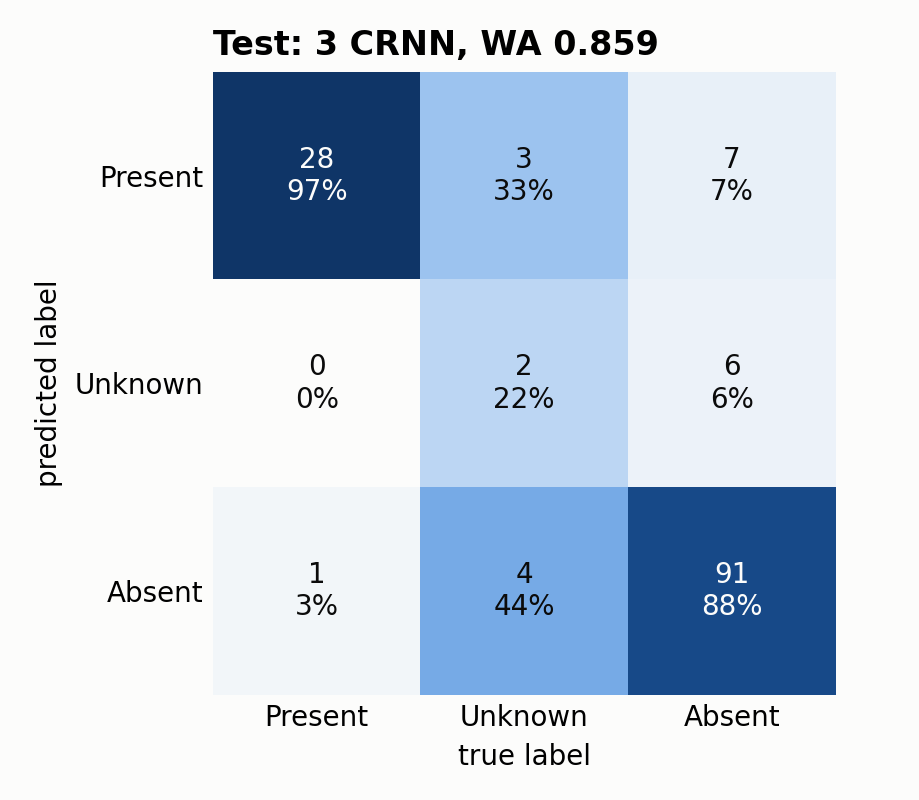

In [47]:
%matplotlib inline
from IPython.display import Image
Image(filename=str(T.RESULTS_DIR / "figures" / "confusion_matrix_test.png"), width=420)

#### 3.3. What the test results show

- **Test WA 0.859** (validation 0.824, always predicting Present 0.525). Our choices held up on unseen patients:
  picking among 13 experiments on validation could have favoured a model that only works on those 146 patients,
  and the test score shows it did not. The test set has fewer Unknown patients than validation (9 against 13),
  and Unknown is the class the model gets wrong most, which explains part of the higher score.
- **The errors lean toward Present on purpose.** The metric counts a missed murmur 5 times more than a false
  alarm, so the thresholds tuned on validation trade false alarms for almost no missed murmurs (28 of 29 found).
- **Unknown is a recording-quality label, not a sound.** The Unknown patients end up split between Present and
  Absent, meaning they sound like one of the two. 4 of the 9 Unknown patients were classified as Absent; in
  practice those children would go home without the second examination they need.
- **Future work:** detect noisy recordings, so the model can flag them for a new recording instead of guessing.